# State AI Policy: shared data preparation

This notebook prepares the source CSV for our supervised and topic analyses. It keeps all **2,571 records and 29 original fields**, then adds normalized text, parsed dates and review flags.

The first pass found **484 records with blank summaries and extracts**. These records still have bill text and remain in the prepared table.

Source: Bhargava and Soliman, [U.S. State AI Legislation Corpus, version 4](https://zenodo.org/records/20781731), `Final_Database_10.csv`. The repository stores this snapshot as `data/raw/Final_Database.csv`.

## 1. Setup

Run from the repository root or `josue_src/`. Install the packages in `notebook-requirements.txt` once. The preparation scripts themselves use only Python's standard library.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Support opening the notebook from either the repository or its own folder.
package_dir = Path.cwd() if Path("prepare.py").exists() else Path.cwd() / "josue_src"
sys.path.insert(0, str(package_dir))

import common_records
import pipeline
import prepare

source = Path(os.environ.get("COMMON_INTAKE_SOURCE", pipeline.DEFAULT_SOURCE))
output = Path(os.environ.get("COMMON_INTAKE_OUTPUT", pipeline.DEFAULT_OUTPUT))
pd.set_option("display.max_colwidth", 65)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## 2. Prepare the data

The command checks the source snapshot, prepares the fields and validates the output. Original values remain in their original columns. New columns use names such as `normalized__Bill_Text` and `introduction_date_iso`.

In [2]:
receipt = prepare.prepare(source, output)
records, contract = common_records.load_common_records(output)
common = pd.DataFrame.from_records(records)

display(pd.DataFrame({
    "Check": ["Source records", "Original fields", "Prepared columns", "Rows dropped or merged"],
    "Result": [len(common), receipt["source_columns"], len(common.columns),
               receipt["checks"]["rows_dropped_or_merged"]],
}))

,Check,Result
0,Source records,2571
1,Original fields,29
2,Prepared columns,152
3,Rows dropped or merged,0


## 3. See what changed

Dates are stored in `YYYY-MM-DD` format so they can be compared consistently. For Alaska HCR 3, the recorded text version is later than the introduction date. Parsing makes that timing visible; it does not correct the source or decide which version to model.

In [3]:
date_columns = [
    "Jurisdiction", "Bill_Number", "Introduction_Date", "introduction_date_iso",
    "Version_Date", "version_date_iso",
]
alaska_hcr3 = common.loc[
    (common["Jurisdiction"] == "Alaska") & (common["Bill_Number"] == "HCR 3"),
    date_columns,
]
display(alaska_hcr3.reset_index(drop=True))

,Jurisdiction,Bill_Number,Introduction_Date,introduction_date_iso,Version_Date,version_date_iso
0,Alaska,HCR 3,02/26/2025,2025-02-26,04/11/2025,2025-04-11


Text normalization combines repeated whitespace and normalizes Unicode. It preserves capitalization, punctuation and wording. The short example below uses `repr()` to make line breaks and extra spaces visible.

In [4]:
changed_text = common["Bill_Text"] != common["normalized__Bill_Text"]
example = common.loc[changed_text].iloc[0]

print(f"{example['Jurisdiction']} {example['Bill_Number']}")
print("Original:", repr(example["Bill_Text"][:120]))
print("Prepared:", repr(example["normalized__Bill_Text"][:120]))

Alabama H 208
Original: 'HB208 INTRODUCED\nI4K5ZW6-1\nBy Representative Shaw\nRFD: State Government\nFirst Read: 06-Feb-25\nSYNOPSIS:\nUnder existing l'
Prepared: 'HB208 INTRODUCED I4K5ZW6-1 By Representative Shaw RFD: State Government First Read: 06-Feb-25 SYNOPSIS: Under existing l'


## 4. Check text coverage

The four text fields serve different purposes. Count their blank cells separately before choosing inputs. A populated cell can still contain a placeholder, so coverage alone does not establish useful text.

In [5]:
audit = json.loads((output / "common_input_audit.json").read_text(encoding="utf-8"))
coverage = pd.DataFrame.from_dict(audit["raw_text_coverage"], orient="index")
coverage = coverage[["raw_nonblank_rows", "raw_blank_rows"]]
coverage.columns = ["Nonblank", "Blank"]
coverage.index.name = "Text field"
display(coverage)

,Nonblank,Blank
Text field,,
Bill_Text,2571,0
NCSL_Summary,2571,0
summary,2087,484
bill_extracts,2087,484


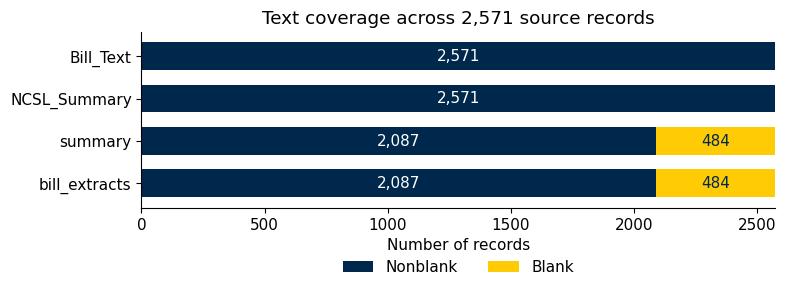

In [6]:
ax = coverage.plot.barh(
    stacked=True, figsize=(8, 3.2), color=["#00274C", "#FFCB05"], width=0.65,
)
ax.invert_yaxis()
ax.set_title(f"Text coverage across {len(common):,} source records")
ax.set_xlabel("Number of records")
ax.set_ylabel("")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
for bars in ax.containers:
    labels = [f"{int(bar.get_width()):,}" if bar.get_width() else "" for bar in bars]
    color = "white" if bars is ax.containers[0] else "#00274C"
    ax.bar_label(bars, labels=labels, label_type="center", color=color)
plt.tight_layout()
plt.show()

Bill text and NCSL descriptions are populated throughout the snapshot. The separate summary and extract fields are both blank on the same 484 records. Keep these records in the shared table; each analysis can choose its own filtering rule.

## 5. Review the flagged records

Flags identify cases to inspect. A later text version may reveal a bill's outcome, and identical wording does not necessarily mean two records describe the same bill. No rows are corrected or removed by these checks.

In [7]:
reason_labels = {
    "version_before_introduction": "Text version before introduction",
    "version_after_introduction": "Text version after introduction",
    "bill_title_missing": "Missing bill title",
    "exact_normalized_text_duplicate_flag": "Identical normalized bill text",
}
flag_counts = pd.DataFrame([
    {"Check": reason_labels[reason], "Records": count}
    for reason, count in audit["review_queue"]["reason_counts"].items()
])
display(flag_counts)
print(f"{audit['review_queue']['distinct_source_records']:,} records have at least one flag.")
print("A record can appear under more than one check.")

,Check,Records
0,Text version before introduction,13
1,Text version after introduction,947
2,Missing bill title,32
3,Identical normalized bill text,8


983 records have at least one flag.
A record can appear under more than one check.


## 6. Use the prepared table

Select the columns needed for an analysis and keep `row_locator` to trace each record back to the source. The full table includes diagnostic columns that are not model features. [The field guide](common-data-contract.md) explains the column groups.

`Bill_Status` and `Bill_Status_Grouped` describe recorded legislative outcomes. Lowercase `status` is publisher processing metadata. Review text timing before using it to distinguish outcomes.

In [8]:
preview_columns = [
    "Jurisdiction", "Bill_Number", "introduction_date_iso", "Bill_Status",
]
display(common[preview_columns].head())

,Jurisdiction,Bill_Number,introduction_date_iso,Bill_Status
0,Alabama,H 208,2025-02-06,Failed - Adjourned
1,Alabama,H 365,2025-02-27,Enacted
2,Alabama,H 515,2025-04-03,Failed - Adjourned
3,Alabama,H 516,2025-04-03,Failed - Adjourned
4,Alabama,H 557,2025-04-09,Failed - Adjourned


Values loaded through `load_common_records()` are strings, including empty strings. Pandas `dropna()` alone will not remove blank text; decide that filter in the analysis notebook.

The next data step is to inspect flagged records and record any agreed corrections separately. The optional [review log](review_tools/README.md) keeps these notes across preparation reruns.